## Se asegura la instalación del framework Tensorflow
Tensorflow es una plataforma de desarrollo creada por Google para la creación, entrenamiento e implementación de modelos de Machine Learning (Aprendizaje automático) y de Deep Learning (Aprendizaje profundo) de manera fácil e intuitiva, es este caso una red neuronal

## Se importan las librerias necesarias
- Pandas: Es la libreria estándar en python para el manejo de estructuras de datos tabulares, en este caso para cargar el archivo .csv e inspeccionar el dataset
- Numpy: Es una libreria para computación científica y manejo de matrices, en este caso nos brinda de operaciones de bajo nivel necesarias para la red neuronal
- train_test_split, LabelEncoder y StandardScaler son son unidades de sklearn para separar el dataset aleatoriamente en una parte para el entrenamiento y otra parte para la prueba, también, unidades para el preprocesamiento de los datos antes de empezar el entrenamiento (codificación y escalado)
- pyplot es una libreria para la generación de gráficos, en este caso para el gráfico de la curva de rendimiento (precisión a lo largo de las épocas)

In [4]:

#Importamos librerias necesarias para el análisis
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
import matplotlib.pyplot as plt


# Preparación de los datos

## Lectura del archivo .csv

Usando pandas se lee el archivo .csv 'titanic.csv' y con .head se muestra los primeros registros

*Notar que hay valores nulos, valores muy diversos y características no importantes*

In [5]:
#Trabajar con el data frame
data = pd.read_csv('titanic.csv')

In [6]:
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Se seleccionan características relevantes para el modelos, y se descartan Passengerid (solamente representa el numero de pasajero), Name (solamnete es el nombre del pasajero), Ticket y Cabin

Además, se eliminan los registros con valores nulos, para tener el data frame limpio de valores nulos

In [7]:
features = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare','Embarked']
data = data[features + ['Survived']].dropna()

In [8]:
data

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,male,22.0,1,0,7.2500,S,0
1,1,female,38.0,1,0,71.2833,C,1
2,3,female,26.0,0,0,7.9250,S,1
3,1,female,35.0,1,0,53.1000,S,1
4,3,male,35.0,0,0,8.0500,S,0
...,...,...,...,...,...,...,...,...
885,3,female,39.0,0,5,29.1250,Q,0
886,2,male,27.0,0,0,13.0000,S,0
887,1,female,19.0,0,0,30.0000,S,1
889,1,male,26.0,0,0,30.0000,C,1


## Codificación de variables 
Se usa un objeto LabelEncoder y su función de fit (detecta las categorías únicas de cada columna) y trannsform (sobreescribe en la columna los valores numéricos correspondientes a cada categoría)

In [9]:
label_encoders = {}
for column in ['Sex', 'Embarked']:
    le = LabelEncoder()
    data[column] = le.fit_transform(data[column])

## Separación del Input (X) y el Output (y)

En X se guardan todos los valores de la data a excepción de el 'Survived' ya que este es la salida, que se guarda en y

In [10]:
#Separar características (x) y etiquetas (y)
X = data.drop('Survived', axis=1).values
y = data['Survived'].values

In [11]:
X

array([[ 3.    ,  1.    , 22.    , ...,  0.    ,  7.25  ,  2.    ],
       [ 1.    ,  0.    , 38.    , ...,  0.    , 71.2833,  0.    ],
       [ 3.    ,  0.    , 26.    , ...,  0.    ,  7.925 ,  2.    ],
       ...,
       [ 1.    ,  0.    , 19.    , ...,  0.    , 30.    ,  2.    ],
       [ 1.    ,  1.    , 26.    , ...,  0.    , 30.    ,  0.    ],
       [ 3.    ,  1.    , 32.    , ...,  0.    ,  7.75  ,  1.    ]],
      shape=(712, 7))

In [12]:
y

array([0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0,
       1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0,
       1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0,
       1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0,
       1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 0,

## Escalado de las variables
Con un objeto de StandardScaler se escalan los registros de entrada, esto es importante para que variables con valores numéricos mas grandes no se interpongan en otras con menor rango

In [13]:
#Escalar las variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## Division Entrenamiento/Prueba

Se hace la division con tran_test_split aleatoria de los datos que se usarán para el entrenamiento y con los que se harán pruebas

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size= 0.2, random_state= 42)

# Arquitectura de la Red Neuronal

## Definir el modelos

Se construye el modelo de la red secuencial, es decir, una capa (layer) va después de la otra; y se asignan 3 capas (2 ocultas y la de salida), la primera de 16 neuronas y la segunda de 8 neuronas, ambas con la funcion de activación Relu (Rectified Linear Unit o Unidad Lineal Rectificada); finalmente la capa de salida con la funcion de activacion sigmoidal ideal para modelos de predicción binarios (1 y 0).

## Compilar el modelo

Se le da la orden a keras de preparar el modelo de una linea abstracta a un modelo real, se define el motor de optmización (es el encargado de actualizar los pesos en el retroceso), la función de pérdida (mide que tan equivocada están las predicciones, en este caso de usa la entropía cruzada binaria que penaliza cuando se predice erroneamente) y las métricas (miden que tan bueno es el modelo).

In [21]:
#Definir el modelo de la red neuronal
model = keras.Sequential([
    layers.Dense(16, activation='relu', input_shape=(7, )),
    layers.Dense(8, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

In [16]:
#Compilar el modelo
model.compile(optimizer='adam', loss= 'binary_crossentropy', metrics=['accuracy'])

In [17]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

## Entrenamiento del modelo

Fit es la instrucción donde se ejecuta el entrenamiento del modelo, se le da los valores de entrada y salida para el entrenamiento, el número de épocas (total de pasadas que el modelo hará a todos los datos, en este caso el modelo aprenderá de todos los datos 500 veces), el batch_size divide los datos en lotes o bloques de 32 muestras con el objetivo de hacer el entrenamiento más eficiente, se separan el 20% de los datos para validación (estos no son usados para entrenamiento solamente al final de cada época para poder medir que tan buen modelo es) y el verbose controla la interfaz visual de la consola.

In [18]:
#Entrenar modelo
history = model.fit(X_train, y_train, epochs=500,
                    batch_size=32, validation_split= 0.2, verbose=1)

Epoch 1/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 122ms/step - accuracy: 0.3802 - loss: 0.7086 - val_accuracy: 0.3772 - val_loss: 0.7233
Epoch 2/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5033 - loss: 0.6837 - val_accuracy: 0.5000 - val_loss: 0.6998
Epoch 3/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6659 - loss: 0.6631 - val_accuracy: 0.7018 - val_loss: 0.6802
Epoch 4/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7363 - loss: 0.6462 - val_accuracy: 0.7105 - val_loss: 0.6640
Epoch 5/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7516 - loss: 0.6307 - val_accuracy: 0.7018 - val_loss: 0.6493
Epoch 6/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7648 - loss: 0.6154 - val_accuracy: 0.7105 - val_loss: 0.6353
Epoch 7/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7714 - loss: 0.5999 - val_accuracy: 0.7105 - val_loss: 0.6210
Epoch 8/500
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.7802 - loss: 0.5839 - val_accuracy: 0

In [19]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print(f"Precisión del conjunto de prueba: {test_accuracy:.4f}")

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7622 - loss: 0.6463
Precisión del conjunto de prueba: 0.7622


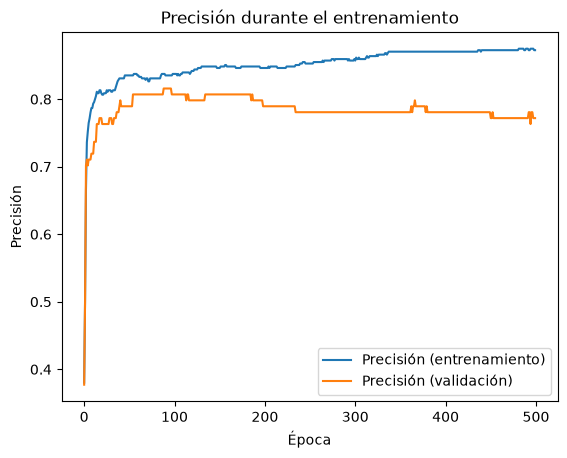

In [20]:
plt.plot(history.history['accuracy'], label='Precisión (entrenamiento)')
plt.plot(history.history['val_accuracy'], label='Precisión (validación)')

plt.title('Precisión durante el entrenamiento')
plt.xlabel('Época')
plt.ylabel('Precisión')
plt.legend()
plt.show()